# Cài đặt và Import thư viện

In [1]:
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mô hình
import lightgbm as lgb
import xgboost as xgb

# Tối ưu siêu tham số
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Đánh giá
from sklearn.metrics import (
    classification_report,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# Đường dẫn đến thư mục chứa dữ liệu đã xử lý
DATA_PATH = r'D:\AI66A_group_10_Topic_7\src\data\processed'

# 1. Load dữ liệu đã tiền xử lý

In [2]:

def load_data(path):
    X_train_res = joblib.load(os.path.join(path, 'X_train_res.pkl'))
    y_train_res = joblib.load(os.path.join(path, 'y_train_res.pkl'))
    X_test = joblib.load(os.path.join(path, 'X_test.pkl'))
    y_test = joblib.load(os.path.join(path, 'y_test.pkl'))
    X_val = joblib.load(os.path.join(path, "X_val.pkl"))
    y_val = joblib.load(os.path.join(path, 'y_val.pkl'))
    feature_cols = joblib.load(os.path.join(path, 'feature_cols.pkl'))
    return X_train_res, y_train_res, X_test, y_test, X_val, y_val, feature_cols

X_train_res, y_train_res, X_test, y_test, X_val, y_val, feature_cols = load_data(DATA_PATH)
print(f"Trainingn set (After SMOTE): {X_train_res.shape}")
print(f"Test set: {X_test.shape}")
print(f"Validation set: {X_val.shape}")


Trainingn set (After SMOTE): (452082, 28)
Test set: (89197, 28)
Validation set: (89197, 28)


# 2. LightGBM training

In [3]:
print("\n--- Đang huấn luyện LightGBM ---")
lgb_model = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
    tree_method='hist',
    max_depth=6
)
lgb_model.fit(X_train_res, y_train_res)


--- Đang huấn luyện LightGBM ---


LGBMClassifier(learning_rate=0.05, max_depth=6, n_estimators=1000, n_jobs=-1,
               random_state=42, tree_method='hist', verbose=-1)

## 3. XGBoost training

In [4]:
print("--- Đang huấn luyện XGBoost ---")
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,  
    tree_method='hist',
    verbose=-1,
    num_leaves=31
    
)
xgb_model.fit(X_train_res, y_train_res)

--- Đang huấn luyện XGBoost ---


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [17:59:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "num_leaves", "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=-1, num_leaves=31, ...)

# 4. Baseline Evaluation (trước khi tối ưu Optuna)

In [5]:
def calculate_metrics(y_true, y_pred, y_prob, label=""):
    metrics = {
        "F1": f1_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }
    if label:
        print(f"\n=== {label} ===")
        for k, v in metrics.items():
            print(f"  {k}: {v:.4f}")
    return metrics

# --- Baseline: đánh giá trên val set ---
lgb_val_preds   = lgb_model.predict(X_val)
lgb_val_probs   = lgb_model.predict_proba(X_val)[:, 1]
xgb_val_preds   = xgb_model.predict(X_val)
xgb_val_probs   = xgb_model.predict_proba(X_val)[:, 1]

lgb_baseline_val = calculate_metrics(y_val, lgb_val_preds, lgb_val_probs, "LightGBM Baseline – Val")
xgb_baseline_val = calculate_metrics(y_val, xgb_val_preds, xgb_val_probs, "XGBoost Baseline – Val")

# --- Baseline: đánh giá trên test set ---
lgb_test_preds  = lgb_model.predict(X_test)
lgb_test_probs  = lgb_model.predict_proba(X_test)[:, 1]
xgb_test_preds  = xgb_model.predict(X_test)
xgb_test_probs  = xgb_model.predict_proba(X_test)[:, 1]

lgb_baseline_test = calculate_metrics(y_test, lgb_test_preds, lgb_test_probs, "LightGBM Baseline – Test")
xgb_baseline_test = calculate_metrics(y_test, xgb_test_preds, xgb_test_probs, "XGBoost Baseline – Test")

# Bảng tóm tắt baseline
baseline_df = pd.DataFrame(
    [lgb_baseline_val, lgb_baseline_test, xgb_baseline_val, xgb_baseline_test],
    index=["LightGBM Val", "LightGBM Test", "XGBoost Val", "XGBoost Test"]
)
print("\nBảng Baseline:")
display(baseline_df.round(4))

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Baseline – Val ===
  F1: 0.8213
  Recall: 0.7380
  Precision: 0.9257
  ROC-AUC: 0.9988
  PR-AUC: 0.9214

=== XGBoost Baseline – Val ===
  F1: 0.8246
  Recall: 0.7526
  Precision: 0.9118
  ROC-AUC: 0.9988
  PR-AUC: 0.9234


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Baseline – Test ===
  F1: 0.8213
  Recall: 0.7380
  Precision: 0.9257
  ROC-AUC: 0.9988
  PR-AUC: 0.9214

=== XGBoost Baseline – Test ===
  F1: 0.8246
  Recall: 0.7526
  Precision: 0.9118
  ROC-AUC: 0.9988
  PR-AUC: 0.9234

Bảng Baseline:


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Val,0.8213,0.7380,0.9257,0.9988,0.9214
LightGBM Test,0.8213,0.7380,0.9257,0.9988,0.9214
XGBoost Val,0.8246,0.7526,0.9118,0.9988,0.9234
XGBoost Test,0.8246,0.7526,0.9118,0.9988,0.9234


# 5. Optuna – Tối ưu Hyperparameters

## 5a. Optuna – LightGBM (100 trials, metric: PR-AUC trên val set)

In [6]:
def lgb_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 2000),
        "max_depth":         trial.suggest_int("max_depth", 3, 12),
        "learning_rate":     trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "num_leaves":        trial.suggest_int("num_leaves", 20, 300),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample":         trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "random_state": 42,
        "n_jobs": -1,
        "verbose": -1,
    }
    model = lgb.LGBMClassifier(**params)
    model.fit(X_train_res, y_train_res)
    probs = model.predict_proba(X_val)[:, 1]
    return average_precision_score(y_val, probs)

lgb_study = optuna.create_study(direction="maximize", study_name="LightGBM-PRAUC")
lgb_study.optimize(lgb_objective, n_trials=100, show_progress_bar=True)

print(f"\nLightGBM best PR-AUC (val): {lgb_study.best_value:.4f}")
print("Best params:", lgb_study.best_params)

  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\valida


LightGBM best PR-AUC (val): 0.9319
Best params: {'n_estimators': 1588, 'max_depth': 8, 'learning_rate': 0.011111730153570632, 'num_leaves': 262, 'min_child_samples': 6, 'subsample': 0.7675345232911098, 'colsample_bytree': 0.5125626108583482}


## 5b. Optuna – XGBoost (100 trials, metric: PR-AUC trên val set)

In [7]:
def xgb_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 2000),
        "max_depth":         trial.suggest_int("max_depth", 3, 12),
        "learning_rate":     trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "subsample":         trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight":  trial.suggest_int("min_child_weight", 1, 20),
        "scale_pos_weight":  trial.suggest_float("scale_pos_weight", 1.0, 10.0),
        "random_state": 42,
        "n_jobs": -1,
        "tree_method": "hist",
        "eval_metric": "aucpr",
    }
    model = xgb.XGBClassifier(**params)
    model.fit(X_train_res, y_train_res)
    probs = model.predict_proba(X_val)[:, 1]
    return average_precision_score(y_val, probs)

xgb_study = optuna.create_study(direction="maximize", study_name="XGBoost-PRAUC")
xgb_study.optimize(xgb_objective, n_trials=100, show_progress_bar=True)

print(f"\nXGBoost best PR-AUC (val): {xgb_study.best_value:.4f}")
print("Best params:", xgb_study.best_params)

  0%|          | 0/100 [00:00<?, ?it/s]


XGBoost best PR-AUC (val): 0.9306
Best params: {'n_estimators': 1373, 'max_depth': 8, 'learning_rate': 0.0070295261563991405, 'subsample': 0.9973124683007342, 'colsample_bytree': 0.5225725607254758, 'min_child_weight': 13, 'scale_pos_weight': 5.084119553737549}


# 6. Retrain với best params từ Optuna

In [8]:
# --- Retrain LightGBM ---
lgb_best = lgb.LGBMClassifier(
    **lgb_study.best_params,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)
lgb_best.fit(X_train_res, y_train_res)
print("LightGBM retrained with best params.")

# --- Retrain XGBoost ---
xgb_best = xgb.XGBClassifier(
    **xgb_study.best_params,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    eval_metric="aucpr",
)
xgb_best.fit(X_train_res, y_train_res)
print("XGBoost retrained with best params.")

LightGBM retrained with best params.
XGBoost retrained with best params.


# 7. Đánh giá sau Optuna – So sánh trước/sau trên Val Set

In [15]:
# Đánh giá trên val set sau Optuna
lgb_opt_val_preds = lgb_best.predict(X_val)
lgb_opt_val_probs = lgb_best.predict_proba(X_val)[:, 1]
xgb_opt_val_preds = xgb_best.predict(X_val)
xgb_opt_val_probs = xgb_best.predict_proba(X_val)[:, 1]

lgb_opt_val = calculate_metrics(y_val, lgb_opt_val_preds, lgb_opt_val_probs, "LightGBM Optuna – Val")
xgb_opt_val = calculate_metrics(y_val, xgb_opt_val_preds, xgb_opt_val_probs, "XGBoost Optuna – Val")

# Bảng so sánh trước / sau Optuna trên Val Set
val_comparison = pd.DataFrame(
    [lgb_baseline_val, lgb_opt_val, xgb_baseline_val, xgb_opt_val],
    index=["LightGBM Baseline", "LightGBM Optuna", "XGBoost Baseline", "XGBoost Optuna"]
)
print("\n Baseline vs Optuna (Val Set):")
display(val_comparison.round(4))

# Cải thiện PR-AUC
lgb_gain = lgb_opt_val["PR-AUC"] - lgb_baseline_val["PR-AUC"]
xgb_gain = xgb_opt_val["PR-AUC"] - xgb_baseline_val["PR-AUC"]
print(f"\nLightGBM PR-AUC gain: {lgb_gain:+.4f}")
print(f"XGBoost  PR-AUC gain: {xgb_gain:+.4f}")

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Optuna – Val ===
  F1: 0.8195
  Recall: 0.7339
  Precision: 0.9277
  ROC-AUC: 0.9989
  PR-AUC: 0.9319

=== XGBoost Optuna – Val ===
  F1: 0.8357
  Recall: 0.8669
  Precision: 0.8066
  ROC-AUC: 0.9989
  PR-AUC: 0.9306

 Baseline vs Optuna (Val Set):


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Baseline,0.8213,0.7380,0.9257,0.9988,0.9214
LightGBM Optuna,0.8195,0.7339,0.9277,0.9989,0.9319
XGBoost Baseline,0.8246,0.7526,0.9118,0.9988,0.9234
XGBoost Optuna,0.8357,0.8669,0.8066,0.9989,0.9306



LightGBM PR-AUC gain: +0.0105
XGBoost  PR-AUC gain: +0.0072


# 8. Đánh giá cuối cùng trên Test Set (chạy 1 lần)

In [16]:
# Đánh giá trên test set (chỉ chạy 1 lần sau khi đã chốt model)
lgb_opt_test_preds = lgb_best.predict(X_test)
lgb_opt_test_probs = lgb_best.predict_proba(X_test)[:, 1]
xgb_opt_test_preds = xgb_best.predict(X_test)
xgb_opt_test_probs = xgb_best.predict_proba(X_test)[:, 1]

lgb_opt_test = calculate_metrics(y_test, lgb_opt_test_preds, lgb_opt_test_probs, "LightGBM Optuna – Test")
xgb_opt_test = calculate_metrics(y_test, xgb_opt_test_preds, xgb_opt_test_probs, "XGBoost Optuna – Test")

print("\nClassification Report – LightGBM Optuna (Test):")
print(classification_report(y_test, lgb_opt_test_preds, target_names=["Non-fraud", "Fraud"]))

print("\nClassification Report – XGBoost Optuna (Test):")
print(classification_report(y_test, xgb_opt_test_preds, target_names=["Non-fraud", "Fraud"]))

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Optuna – Test ===
  F1: 0.8195
  Recall: 0.7339
  Precision: 0.9277
  ROC-AUC: 0.9989
  PR-AUC: 0.9319

=== XGBoost Optuna – Test ===
  F1: 0.8357
  Recall: 0.8669
  Precision: 0.8066
  ROC-AUC: 0.9989
  PR-AUC: 0.9306

Classification Report – LightGBM Optuna (Test):
              precision    recall  f1-score   support

   Non-fraud       1.00      1.00      1.00     88235
       Fraud       0.93      0.73      0.82       962

    accuracy                           1.00     89197
   macro avg       0.96      0.87      0.91     89197
weighted avg       1.00      1.00      1.00     89197


Classification Report – XGBoost Optuna (Test):
              precision    recall  f1-score   support

   Non-fraud       1.00      1.00      1.00     88235
       Fraud       0.81      0.87      0.84       962

    accuracy                           1.00     89197
   macro avg       0.90      0.93      0.92     89197
weighted avg       1.00      1.00      1.00     89197



# 9. So sánh LightGBM vs XGBoost – Chọn model tốt hơn & Cảnh báo overfitting

In [19]:
THRESHOLD = 0.05  # 5% gap cảnh báo

# Bảng tổng hợp sau Optuna
final_df = pd.DataFrame(
    [lgb_opt_val, lgb_opt_test, xgb_opt_val, xgb_opt_test],
    index=["LightGBM Val", "LightGBM Test", "XGBoost Val", "XGBoost Test"]
)
print("=== Metrics Table After Optuna ===")
display(final_df.round(4))

# --- Kiểm tra gap Val vs Test ---
print("\n=== Gap difference:  Val vs Test (PR-AUC) ===")
for name, val_m, test_m in [
    ("LightGBM", lgb_opt_val, lgb_opt_test),
    ("XGBoost",  xgb_opt_val, xgb_opt_test),
]:
    gap = abs(val_m["PR-AUC"] - test_m["PR-AUC"])
    print(f"  {name}: Val PR-AUC={val_m['PR-AUC']:.4f}, Test PR-AUC={test_m['PR-AUC']:.4f} | Gap={gap:.4f}")

# --- So sánh và chọn model tốt hơn ---
print("\n===  LightGBM vs XGBoost (Test Set, Optuna) ===")
compare_test = pd.DataFrame(
    [lgb_opt_test, xgb_opt_test],
    index=["LightGBM Optuna", "XGBoost Optuna"]
)
display(compare_test.round(4))

best_name = "LightGBM" if lgb_opt_test["PR-AUC"] >= xgb_opt_test["PR-AUC"] else "XGBoost"
best_prauc = max(lgb_opt_test["PR-AUC"], xgb_opt_test["PR-AUC"])
print(f"\n>>> Better Model : {best_name} (Test PR-AUC = {best_prauc:.4f})")

=== Metrics Table After Optuna ===


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Val,0.8195,0.7339,0.9277,0.9989,0.9319
LightGBM Test,0.8195,0.7339,0.9277,0.9989,0.9319
XGBoost Val,0.8357,0.8669,0.8066,0.9989,0.9306
XGBoost Test,0.8357,0.8669,0.8066,0.9989,0.9306



=== Gap difference:  Val vs Test (PR-AUC) ===
  LightGBM: Val PR-AUC=0.9319, Test PR-AUC=0.9319 | Gap=0.0000
  XGBoost: Val PR-AUC=0.9306, Test PR-AUC=0.9306 | Gap=0.0000

===  LightGBM vs XGBoost (Test Set, Optuna) ===


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Optuna,0.8195,0.7339,0.9277,0.9989,0.9319
XGBoost Optuna,0.8357,0.8669,0.8066,0.9989,0.9306



>>> Better Model : LightGBM (Test PR-AUC = 0.9319)


# 10. Visualization – Confusion Matrix & Precision-Recall Curve (sau Optuna)

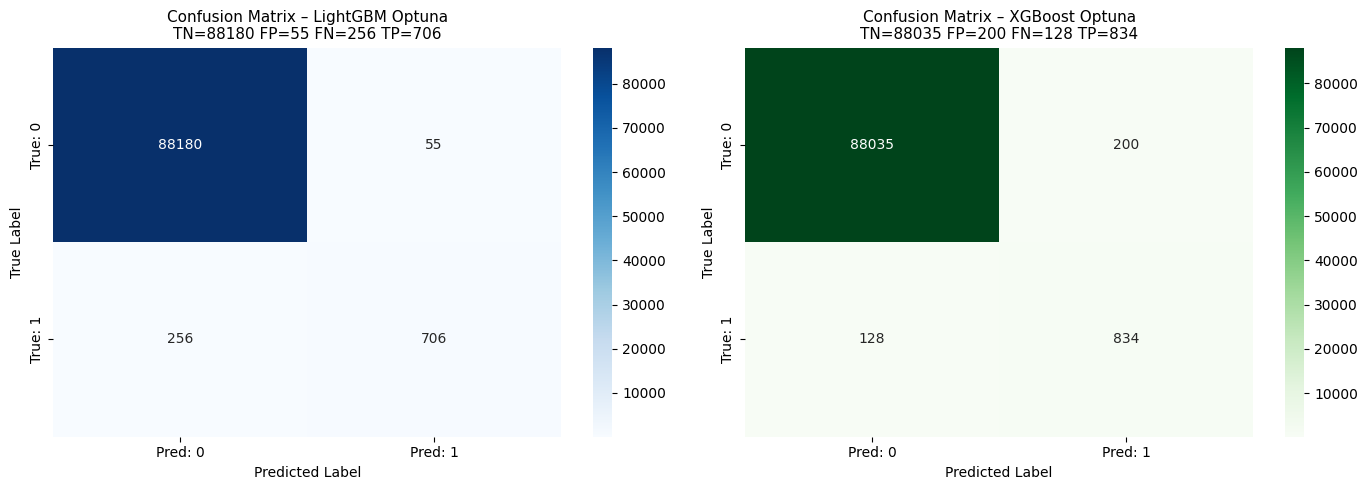

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name, preds, cmap in [
    (axes[0], "LightGBM Optuna", lgb_opt_test_preds, "Blues"),
    (axes[1], "XGBoost Optuna",  xgb_opt_test_preds, "Greens"),
]:
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=cmap,
        xticklabels=["Pred: 0", "Pred: 1"],
        yticklabels=["True: 0", "True: 1"],
        ax=ax,
    )
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"Confusion Matrix – {name}\nTN={tn} FP={fp} FN={fn} TP={tp}", fontsize=11)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

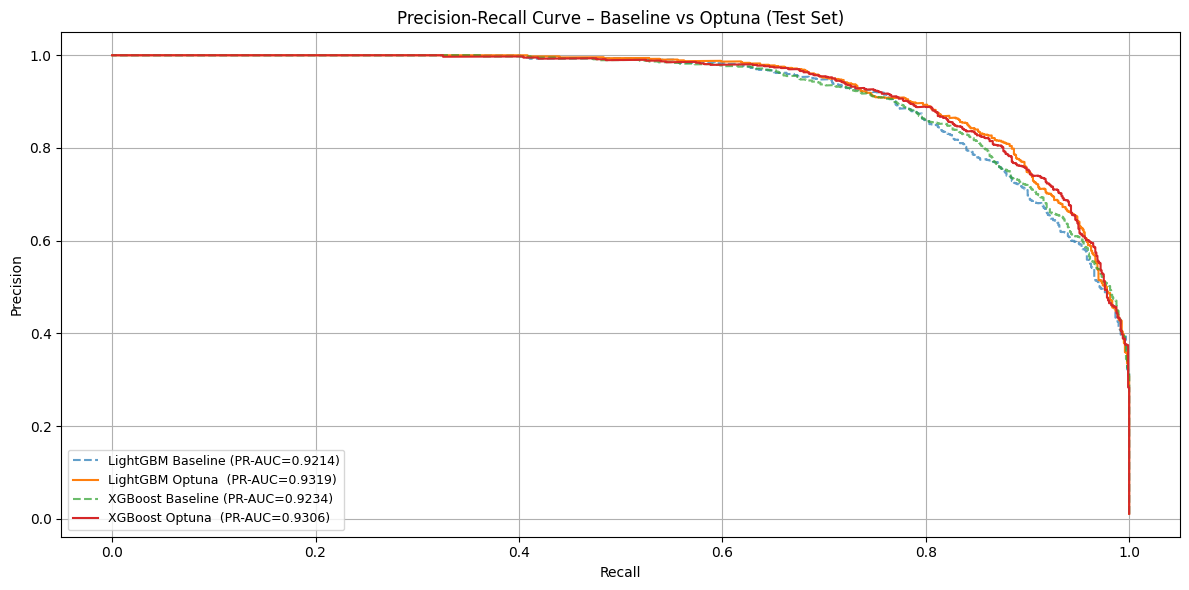

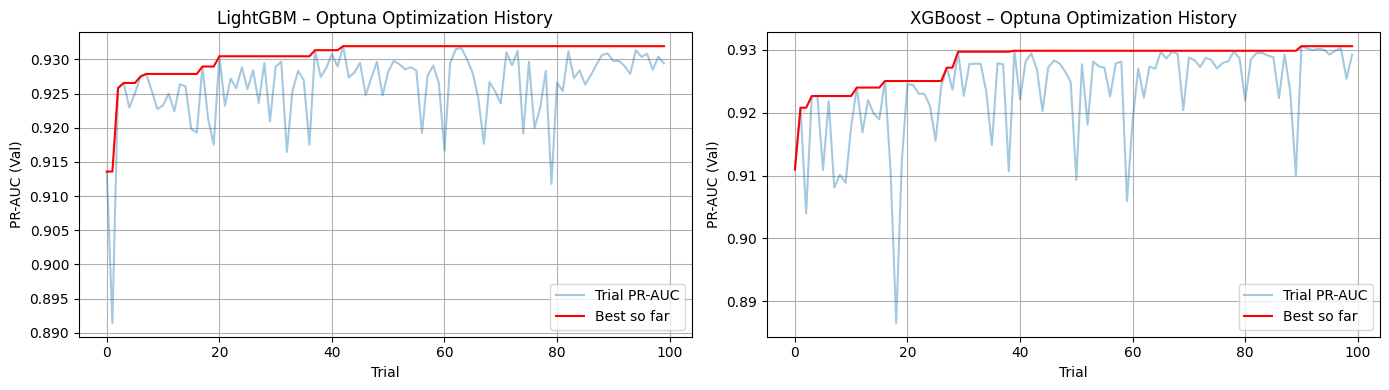

In [13]:
# Precision-Recall Curve – so sánh Baseline vs Optuna
plt.figure(figsize=(12, 6))

for model_name, probs_base, probs_opt in [
    ("LightGBM", lgb_test_probs, lgb_opt_test_probs),
    ("XGBoost",  xgb_test_probs, xgb_opt_test_probs),
]:
    prec_b, rec_b, _ = precision_recall_curve(y_test, probs_base)
    prec_o, rec_o, _ = precision_recall_curve(y_test, probs_opt)
    auc_b = average_precision_score(y_test, probs_base)
    auc_o = average_precision_score(y_test, probs_opt)
    plt.plot(rec_b, prec_b, linestyle="--", label=f"{model_name} Baseline (PR-AUC={auc_b:.4f})", alpha=0.7)
    plt.plot(rec_o, prec_o, linestyle="-",  label=f"{model_name} Optuna  (PR-AUC={auc_o:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – Baseline vs Optuna (Test Set)")
plt.legend(fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

# Optuna optimization history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, study, name in [
    (axes[0], lgb_study, "LightGBM"),
    (axes[1], xgb_study, "XGBoost"),
]:
    values = [t.value for t in study.trials if t.value is not None]
    best_so_far = pd.Series(values).cummax()
    ax.plot(values, alpha=0.4, label="Trial PR-AUC")
    ax.plot(best_so_far.values, color="red", label="Best so far")
    ax.set_title(f"{name} – Optuna Optimization History")
    ax.set_xlabel("Trial")
    ax.set_ylabel("PR-AUC (Val)")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 11. Feature Importance

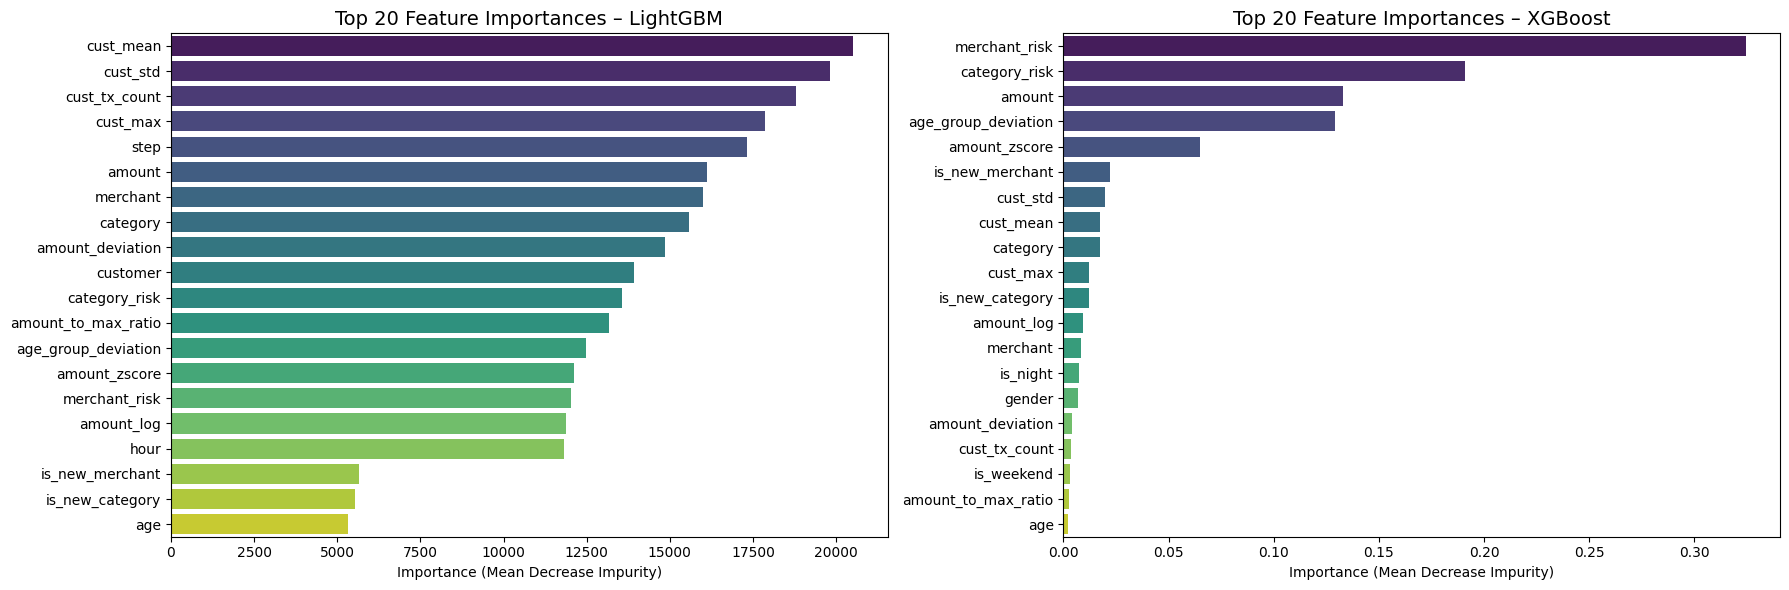


Top 20 features quan trọng nhất – LightGBM:
            feature  importance
          cust_mean       20519
           cust_std       19817
      cust_tx_count       18779
           cust_max       17862
               step       17335
             amount       16113
           merchant       16009
           category       15562
   amount_deviation       14844
           customer       13922
      category_risk       13555
amount_to_max_ratio       13157
age_group_deviation       12484
      amount_zscore       12114
      merchant_risk       12042
         amount_log       11883
               hour       11806
    is_new_merchant        5641
    is_new_category        5524
                age        5336

Top 20 features quan trọng nhất – XGBoost:
            feature  importance
      merchant_risk    0.324477
      category_risk    0.191001
             amount    0.132798
age_group_deviation    0.128942
      amount_zscore    0.064715
    is_new_merchant    0.022195
           cust

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, model, name in [
    (axes[0], lgb_best, "LightGBM"),
    (axes[1], xgb_best, "XGBoost"),
]:
    importance_df = pd.DataFrame({
        'feature':    feature_cols,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False).reset_index(drop=True)

    top_df = importance_df.head(20)

    sns.barplot(
        data=top_df, x='importance', y='feature',
        hue='feature', palette='viridis', legend=False, ax=ax
    )
    ax.set_title(f'Top 20 Feature Importances – {name}', fontsize=14)
    ax.set_xlabel('Importance (Mean Decrease Impurity)')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

# In bảng top 20 cho từng model
for model, name in [
    (lgb_best, "LightGBM"),
    (xgb_best, "XGBoost"),
]:
    importance_df = pd.DataFrame({
        'feature':    feature_cols,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False).reset_index(drop=True)

    print(f"\nTop 20 features quan trọng nhất – {name}:")
    print(importance_df.head(20).to_string(index=False))

In [1]:
MODEL_DIR = os.path.abspath(os.path.join(DATA_PATH, '..', 'models'))
os.makedirs(MODEL_DIR, exist_ok=True)

lgb_model_path = os.path.join(MODEL_DIR, 'lgb_best.pkl')
xgb_model_path = os.path.join(MODEL_DIR, 'xgb_best.pkl')

joblib.dump(lgb_best, lgb_model_path)
joblib.dump(xgb_best, xgb_model_path)

print(f"LightGBM model saved to: {lgb_model_path}")
print(f"XGBoost model saved to: {xgb_model_path}")

NameError: name 'os' is not defined